<center><font size=6> Bank Churn Prediction </font></center>

## Problem Statement

### Context

Businesses like banks which provide service have to worry about problem of 'Customer Churn' i.e. customers leaving and joining another service provider. It is important to understand which aspects of the service influence a customer's decision in this regard. Management can concentrate efforts on improvement of service, keeping in mind these priorities.

### Objective

You as a Data scientist with the  bank need to  build a neural network based classifier that can determine whether a customer will leave the bank  or not in the next 6 months.

### Data Dictionary

* CustomerId: Unique ID which is assigned to each customer

* Surname: Last name of the customer

* CreditScore: It defines the credit history of the customer.
  
* Geography: A customer’s location
   
* Gender: It defines the Gender of the customer
   
* Age: Age of the customer
    
* Tenure: Number of years for which the customer has been with the bank

* NumOfProducts: refers to the number of products that a customer has purchased through the bank.

* Balance: Account balance

* HasCrCard: It is a categorical variable which decides whether the customer has credit card or not.

* EstimatedSalary: Estimated salary

* isActiveMember: Is is a categorical variable which decides whether the customer is active member of the bank or not ( Active member in the sense, using bank products regularly, making transactions etc )

* Exited : whether or not the customer left the bank within six month. It can take two values
** 0=No ( Customer did not leave the bank )
** 1=Yes ( Customer left the bank )

In [62]:
pip install tensorflow

## Importing necessary libraries

In [137]:
# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd
import time

# Libraries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 200)

# to split the data into train and test
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score, recall_score, precision_score, f1_score, classification_report

# to ignore warnings
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf #An end-to-end open source machine learning platform
from tensorflow import keras  # High-level neural networks API for deep learning.
from keras import backend   # Abstraction layer for neural network backend engines.
from keras.models import Sequential  # Model for building NN sequentially.
from keras.layers import Dense, Dropout

# to suppress warnings
import warnings
warnings.filterwarnings("ignore")

In [64]:
# Set the seed using keras.utils.set_random_seed. This will set:
# 1) `numpy` seed
# 2) backend random seed
# 3) `python` random seed
tf.keras.utils.set_random_seed(724)

# If using TensorFlow, this will make GPU ops as deterministic as possible,
# but it will affect the overall performance, so be mindful of that.
tf.config.experimental.enable_op_determinism()

## Loading the dataset

In [65]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [66]:
churn = pd.read_csv('/content/drive/MyDrive/Great Learning/Project 4: Neural Networks/Churn.csv')

In [67]:
churn.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## Data Overview

- Observations
- Sanity Checks

In [68]:
# First Five Rows of the Data Set
churn.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [69]:
# Last Five rows of the Data Set
churn.tail()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1
9999,10000,15628319,Walker,792,France,Female,28,4,130142.79,1,1,0,38190.78,0


In [70]:
# Shape of the data set
churn.shape

(10000, 14)

We can confirm that there are 10,000 rows of data with 14 column's of data which can be used as features.

In [71]:
# Checking the data types of the data set along with missing values
churn.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


We can see that 3 variables/columns are objects and that there are no null or missing values from a cursory glance.
- I can see two columns that need to be dropped in Row Number, Customer Id, and Surname. Need confirmation via analysis to proceed.

### Duplicate Values and Missing Values Identification

In [72]:
churn.duplicated().sum()

0

There are no duplicate values.

In [73]:
churn.isnull().sum()

,0
RowNumber,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0


We can see that there are no null values in the data variables.

In [74]:
for i in churn.describe(include=["int64","float64"]).columns:
    print("Unique values in", i, "are :")
    print(churn[i].value_counts())
    print("*" * 50)

Unique values in RowNumber are :
RowNumber
1        1
6671     1
6664     1
6665     1
6666     1
        ..
3334     1
3335     1
3336     1
3337     1
10000    1
Name: count, Length: 10000, dtype: int64
**************************************************
Unique values in CustomerId are :
CustomerId
15634602    1
15667932    1
15766185    1
15667632    1
15599024    1
           ..
15599078    1
15702300    1
15660735    1
15671390    1
15628319    1
Name: count, Length: 10000, dtype: int64
**************************************************
Unique values in CreditScore are :
CreditScore
850    233
678     63
655     54
705     53
667     53
      ... 
404      1
351      1
365      1
417      1
419      1
Name: count, Length: 460, dtype: int64
**************************************************
Unique values in Age are :
Age
37    478
38    477
35    474
36    456
34    447
33    442
40    432
39    423
32    418
31    404
41    366
29    348
30    327
42    321
43    297
28    273
44  

In [75]:
for i in churn.describe(include=["object"]).columns:
    print("Unique values in", i, "are :")
    print(churn[i].value_counts())
    print("*" * 50)

Unique values in Surname are :
Surname
Smith       32
Scott       29
Martin      29
Walker      28
Brown       26
            ..
Izmailov     1
Bold         1
Bonham       1
Poninski     1
Burbidge     1
Name: count, Length: 2932, dtype: int64
**************************************************
Unique values in Geography are :
Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64
**************************************************
Unique values in Gender are :
Gender
Male      5457
Female    4543
Name: count, dtype: int64
**************************************************


In [76]:
churn.describe().T

,count,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,5.000500e+03,2886.895680,1.00,2500.75,5.000500e+03,7.500250e+03,10000.00
CustomerId,10000.0,1.569094e+07,71936.186123,15565701.00,15628528.25,1.569074e+07,1.575323e+07,15815690.00
CreditScore,10000.0,6.505288e+02,96.653299,350.00,584.00,6.520000e+02,7.180000e+02,850.00
Age,10000.0,3.892180e+01,10.487806,18.00,32.00,3.700000e+01,4.400000e+01,92.00
Tenure,10000.0,5.012800e+00,2.892174,0.00,3.00,5.000000e+00,7.000000e+00,10.00
Balance,10000.0,7.648589e+04,62397.405202,0.00,0.00,9.719854e+04,1.276442e+05,250898.09
NumOfProducts,10000.0,1.530200e+00,0.581654,1.00,1.00,1.000000e+00,2.000000e+00,4.00
HasCrCard,10000.0,7.055000e-01,0.455840,0.00,0.00,1.000000e+00,1.000000e+00,1.00
IsActiveMember,10000.0,5.151000e-01,0.499797,0.00,0.00,1.000000e+00,1.000000e+00,1.00
EstimatedSalary,10000.0,1.000902e+05,57510.492818,11.58,51002.11,1.001939e+05,1.493882e+05,199992.48


We can see that row number and customer id, are two numerical rows that offer no value due to them being in order and being all unique values.
- Mean Credit Score is 652.
- Avg. Age is 37
- We see that Tenure is between 0 - 10 years.
- We see that Exited, HasCrCard, and IsActiveMember are all binary values
- With Exited being 80:20 split in not exited direction.


In [77]:
churn.nunique()

,0
RowNumber,10000
CustomerId,10000
Surname,2932
CreditScore,460
Geography,3
Gender,2
Age,70
Tenure,11
Balance,6382
NumOfProducts,4


The nunique function confirms the thought that RowNumber & CustomerID are all uniques as they match all the rows in the data set.
- there is a relatively event split between males and females in the data set.
- there are 2,932 unique surname values.
- Assuming that 1 means that someone HasCrCard, meaning that roughly 70% of the data set has credit cards
- Assuming that 1 means that the member is active in var IsActiveMember. We see that roughly 51% of the members are active with the bank.


## Exploratory Data Analysis

### Univariate Analysis

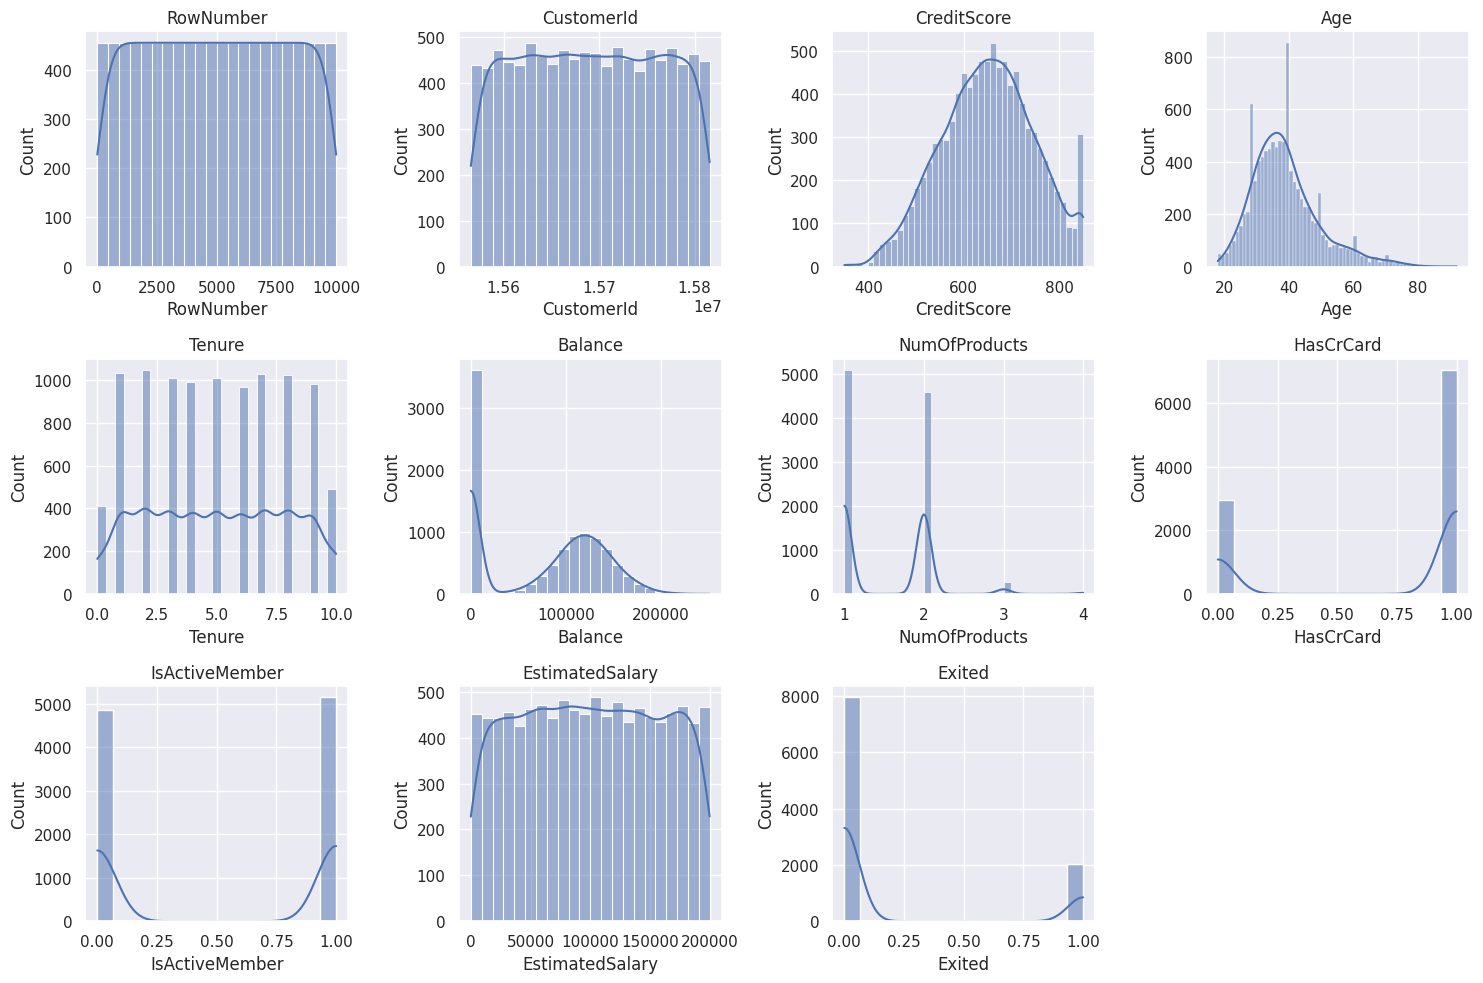

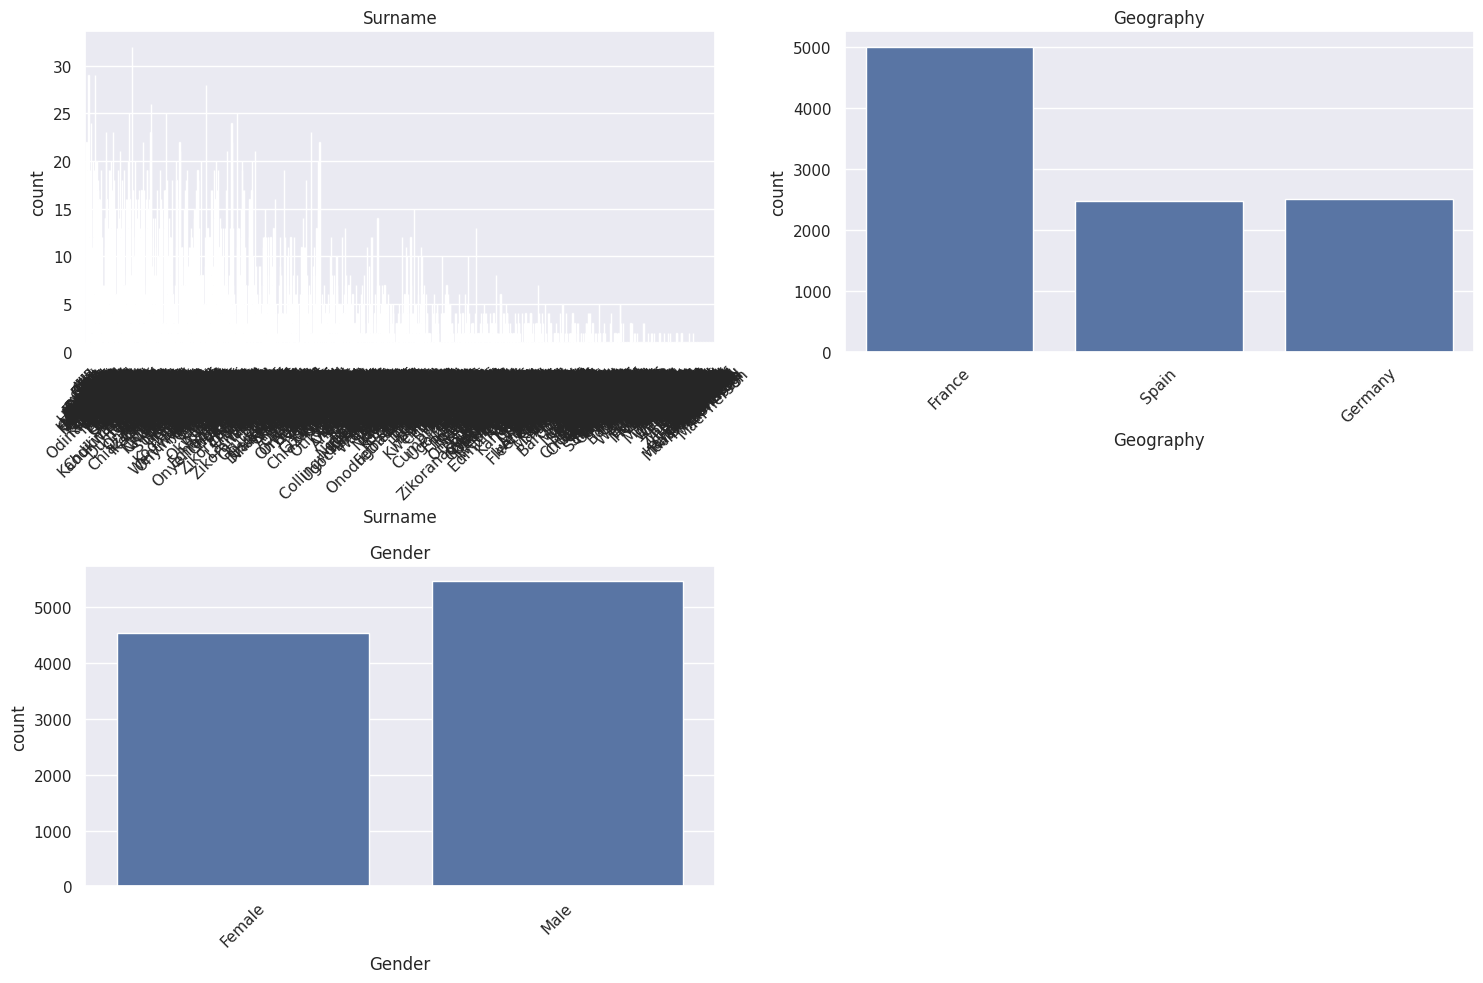

In [78]:
# Histograms for numerical features
plt.figure(figsize=(15, 10))
for i, col in enumerate(churn.select_dtypes(include=['number']).columns):
  plt.subplot(3, 4, i+1)
  sns.histplot(churn[col], kde=True)
  plt.title(col)
plt.tight_layout()
plt.show()

# Count plots for categorical features
plt.figure(figsize=(15, 10))
for i, col in enumerate(churn.select_dtypes(include=['object']).columns):
  plt.subplot(2, 2, i+1)
  sns.countplot(x=col, data=churn)
  plt.title(col)
  plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


- We can see that the univariate analysis supports our previous conclusions from earlier in the file.
- We can see that 50% of the sample are from France.
- We can see that surname does not have any clear value.
- There is a unimodal normal distribution for account balance with an outlier at 0 due to people not having balances
- There is a right skew for credit score and a left skew on age.
- no need to treat ouliers due to any outliers being a natural feature of the industry.

### Bivariate Analysis

In [79]:
# function to plot stacked bar chart


def stacked_barplot(data, predictor, target):
    """
    Print the category counts and plot a stacked bar chart

    data: dataframe
    predictor: independent variable
    target: target variable
    """
    count = data[predictor].nunique()
    sorter = data[target].value_counts().index[-1]
    tab1 = pd.crosstab(data[predictor], data[target], margins=True).sort_values(
        by=sorter, ascending=False
    )
    print(tab1)
    print("-" * 120)
    tab = pd.crosstab(data[predictor], data[target], normalize="index").sort_values(
        by=sorter, ascending=False
    )
    tab.plot(kind="bar", stacked=True, figsize=(count + 1, 5))
    plt.legend(
        loc="lower left",
        frameon=False,
    )
    plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
    plt.show()

Exited     0     1    All
Gender                   
All     7963  2037  10000
Female  3404  1139   4543
Male    4559   898   5457
------------------------------------------------------------------------------------------------------------------------


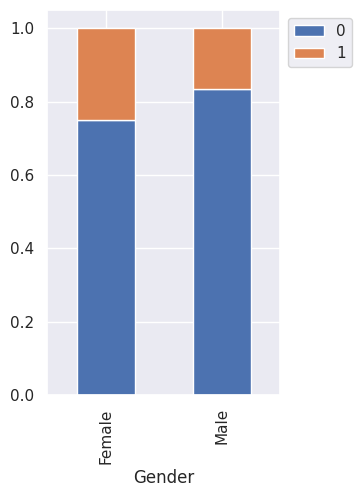

Exited        0     1    All
Geography                   
All        7963  2037  10000
Germany    1695   814   2509
France     4204   810   5014
Spain      2064   413   2477
------------------------------------------------------------------------------------------------------------------------


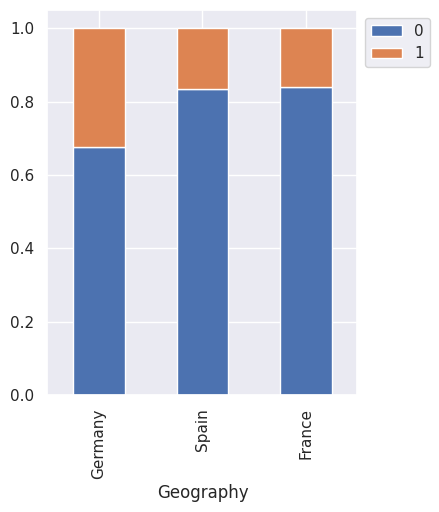

Exited        0     1    All
HasCrCard                   
All        7963  2037  10000
1          5631  1424   7055
0          2332   613   2945
------------------------------------------------------------------------------------------------------------------------


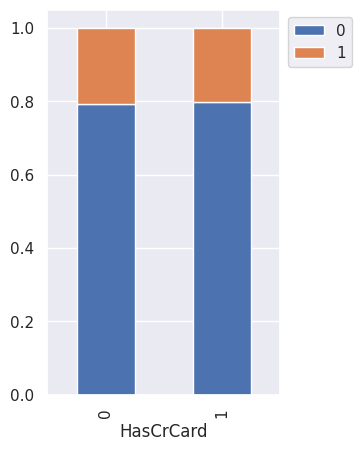

Exited             0     1    All
IsActiveMember                   
All             7963  2037  10000
0               3547  1302   4849
1               4416   735   5151
------------------------------------------------------------------------------------------------------------------------


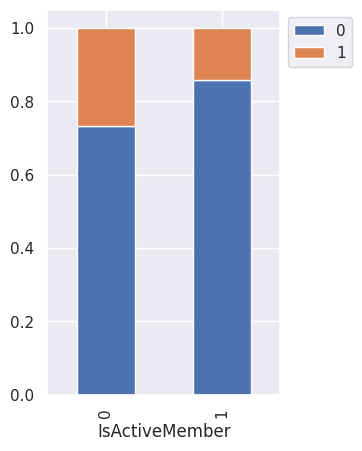

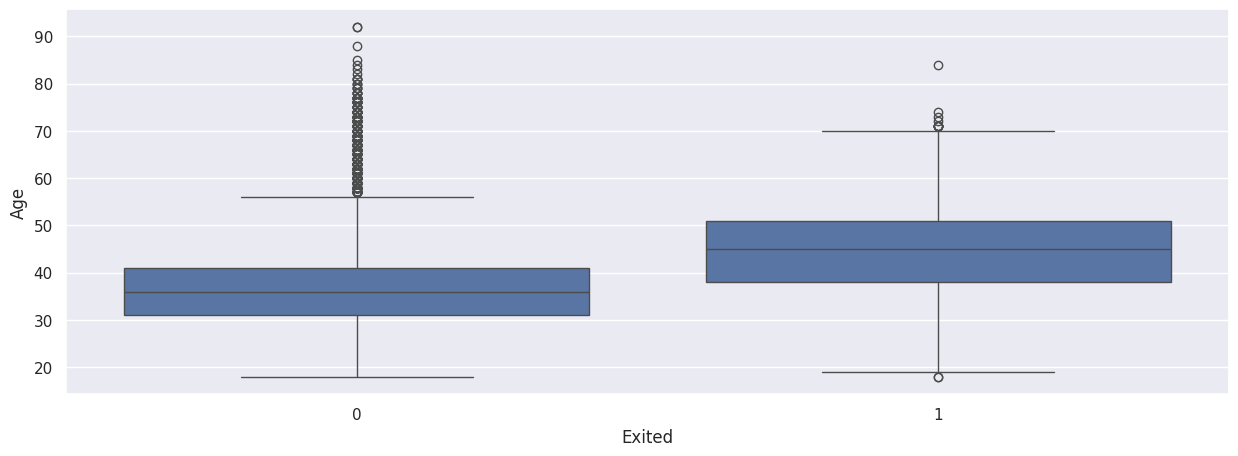

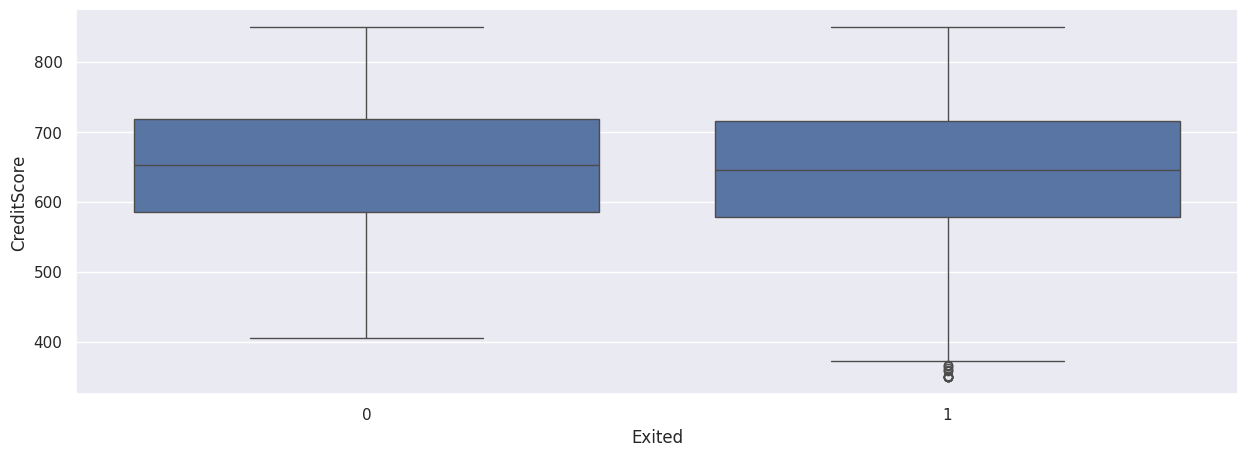

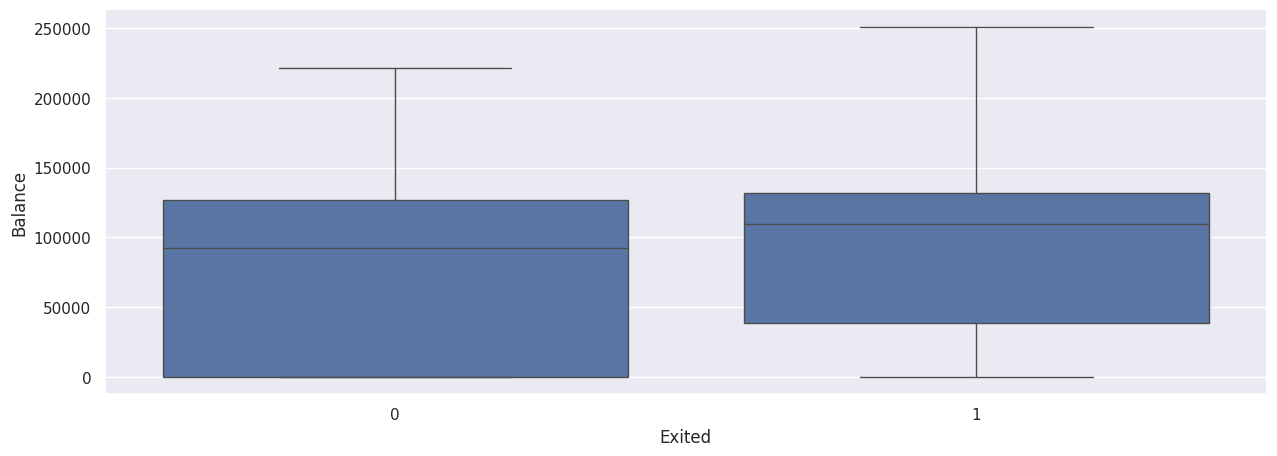

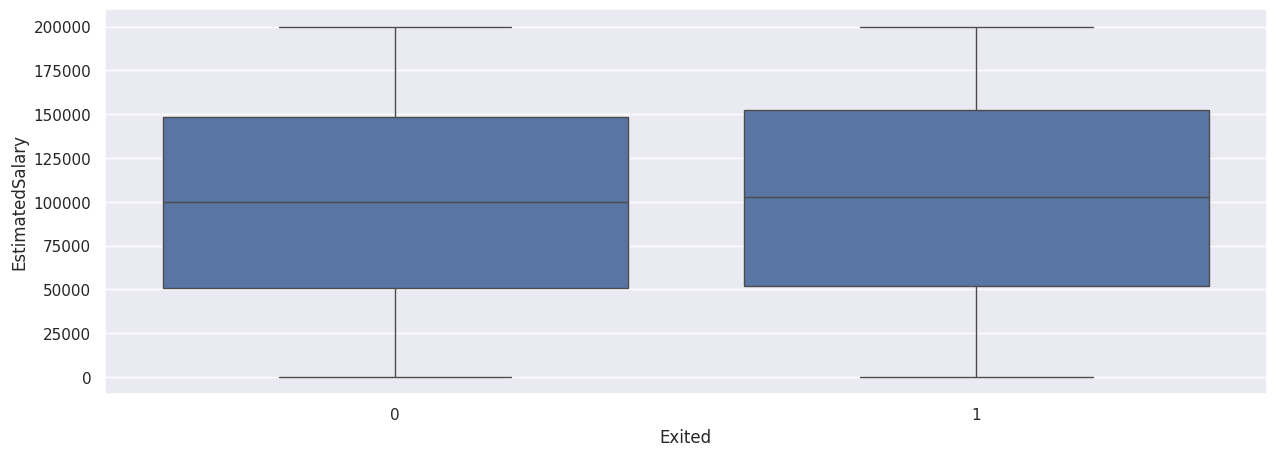

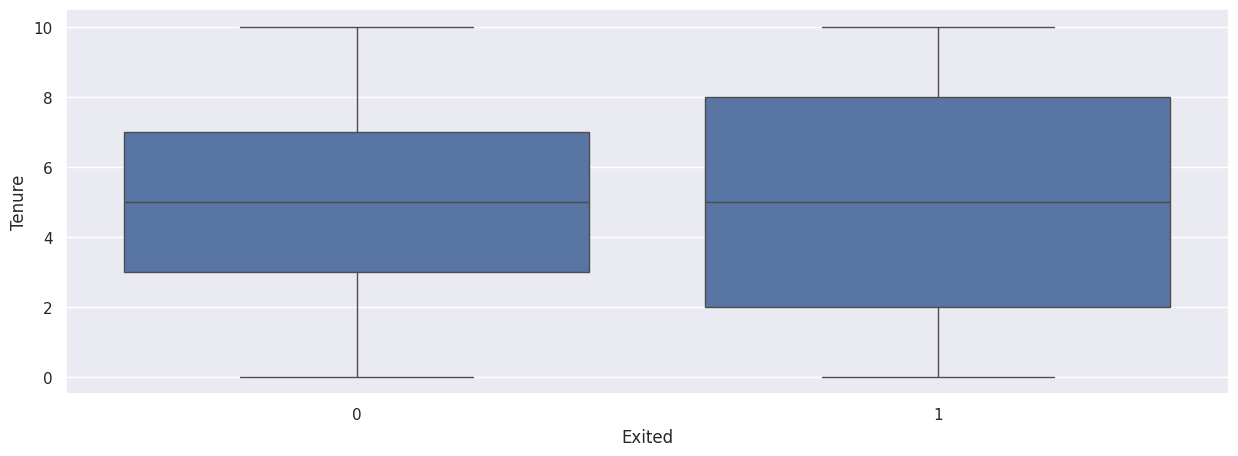

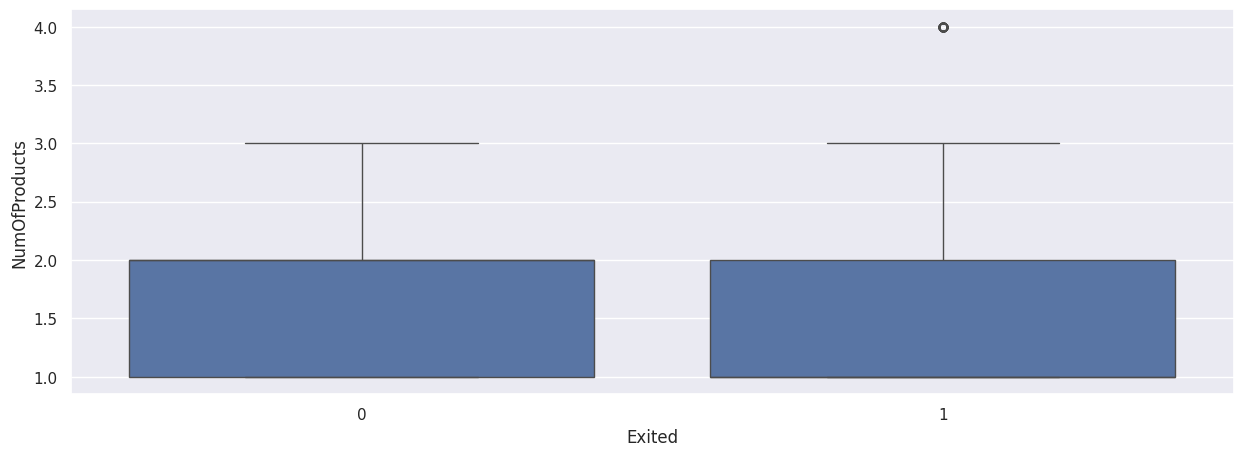

In [80]:
# Gender vs Exited
stacked_barplot(churn, "Gender", "Exited")
# Geography vs Exited
stacked_barplot(churn, "Geography", "Exited")
# HasCrCard vs Exited
stacked_barplot(churn, "HasCrCard", "Exited")
# IsActiveMember vs Exited
stacked_barplot(churn, "IsActiveMember", "Exited")
# Age vs Exited
plt.figure(figsize=(15, 5))
sns.boxplot(x="Exited", y="Age", data=churn)
plt.show()
# CreditScore vs Exited
plt.figure(figsize=(15, 5))
sns.boxplot(x="Exited", y="CreditScore", data=churn)
plt.show()
# Balance vs Exited
plt.figure(figsize=(15, 5))
sns.boxplot(x="Exited", y="Balance", data=churn)
plt.show()
# EstimatedSalary vs Exited
plt.figure(figsize=(15, 5))
sns.boxplot(x="Exited", y="EstimatedSalary", data=churn)
plt.show()
# Tenure vs Exited
plt.figure(figsize=(15, 5))
sns.boxplot(x="Exited", y="Tenure", data=churn)
plt.show()
# NumOfProducts vs Exited
plt.figure(figsize=(15, 5))
sns.boxplot(x="Exited", y="NumOfProducts", data=churn)
plt.show()


- We see that more females have exited the bank
- We see that Germany has the most exits, then Spain, and finally France.
- The proportion of members that leave is the same across those that hold credit cards and those that don't.
- We see that non-active members are more likely to exit or leave the bank than those who are active members.
- Through the box plots, we can see that the median age is higher than those that haven't left the bank. We also see a higher IQR for those that have left the bank than those that didn't leave the bank account.
- The box plot distributions are similar across that left and those that stayed.
- We see that the median balance is higher for those that exited and we see that there is a smallwer IQR for members that left than those that stayed
- We see that estimated salary is roughly the same and tenure, but the central distributions are wider.


## Data Preprocessing

Dropping the columns surname, row number, and customer ID dut to them being a majority uniqe values. And surname plays no role in a customer leaveing the bank.

In [81]:
data = churn.drop(["RowNumber", "CustomerId", "Surname"], axis=1)
data.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [82]:
data.isnull().sum()

,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0
HasCrCard,0
IsActiveMember,0
EstimatedSalary,0


With the irrelavant variables being dropped and no missing values confirmed we can move onto the one hat encoding stage.

### Dummy Variable Creation

In [83]:
# Creating dummy variables for categorical features
data = pd.get_dummies(data, columns=["Geography", "Gender"], drop_first=True, dtype=int)

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CreditScore        10000 non-null  int64  
 1   Age                10000 non-null  int64  
 2   Tenure             10000 non-null  int64  
 3   Balance            10000 non-null  float64
 4   NumOfProducts      10000 non-null  int64  
 5   HasCrCard          10000 non-null  int64  
 6   IsActiveMember     10000 non-null  int64  
 7   EstimatedSalary    10000 non-null  float64
 8   Exited             10000 non-null  int64  
 9   Geography_Germany  10000 non-null  int64  
 10  Geography_Spain    10000 non-null  int64  
 11  Gender_Male        10000 non-null  int64  
dtypes: float64(2), int64(10)
memory usage: 937.6 KB


In [84]:
data.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1,0


Confirm one hat encoding done properly and check no non neumerical values. We see no france and female column as france and female are considered base calculation.

### Train-validation-test Split

In [85]:
# Seperate the independant and dependant variables
X = data.drop(['Exited'],axis=1)
Y = data['Exited']

In [86]:
X.columns

Index(['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Geography_Germany',
       'Geography_Spain', 'Gender_Male'],
      dtype='object')

In [87]:
#Calculating the total number of nan values for each columns.
X.isnull().sum()

,0
CreditScore,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0
HasCrCard,0
IsActiveMember,0
EstimatedSalary,0
Geography_Germany,0
Geography_Spain,0


- No missing values so no need to treat missing values

In [88]:
#Now split data set into test, train, and validation and once split and verify the independant and dependant variables.
# Splitting the dataset into the Training and Test set.
X_train, X_test, y_train, y_test = train_test_split(X,Y, test_size = 0.2, random_state = 42,stratify = Y)

In [89]:
# Splitting the Train dataset into the Training and Validation set.
X_train, X_valid, y_train, y_valid = train_test_split(X_train,y_train, test_size = 0.2, random_state = 42,stratify = y_train)

In [90]:
#Printing the shapes.
print(X_train.shape,y_train.shape)
print(X_valid.shape,y_valid.shape)
print(X_test.shape,y_test.shape)

(6400, 11) (6400,)
(1600, 11) (1600,)
(2000, 11) (2000,)


Confirmed that no data loss

### Data Normalization

- Normalize data after splitting to prevent data leakage.
- From th EDA need to normalize credit score, age, and balance due to various distributions and skews.
- Standardizing the numerical variables to zero mean and unit variance.

In [91]:
transformer = StandardScaler()
X[["CreditScore","Age","Balance"]] = transformer.fit_transform(X[["CreditScore","Age","Balance"]])

## Model Building

### Plotting and Utility Functions

In [92]:
def plot(history, name):
    """
    Function to plot loss/accuracy

    history: an object which stores the metrics and losses.
    name: can be one of Loss or Accuracy
    """
    fig, ax = plt.subplots() #Creating a subplot with figure and axes.
    plt.plot(history.history[name]) #Plotting the train accuracy or train loss
    plt.plot(history.history['val_'+name]) #Plotting the validation accuracy or validation loss

    plt.title('Model ' + name.capitalize()) #Defining the title of the plot.
    plt.ylabel(name.capitalize()) #Capitalizing the first letter.
    plt.xlabel('Epoch') #Defining the label for the x-axis.
    fig.legend(['Train', 'Validation'], loc="outside right upper") #Defining the legend, loc controls the position of the legend.

In [93]:
# defining a function to compute different metrics to check performance of a classification model built using statsmodels
def model_performance_classification(
    model, predictors, target, threshold=0.5
):
    """
    Function to compute different metrics to check classification model performance

    model: classifier
    predictors: independent variables
    target: dependent variable
    threshold: threshold for classifying the observation as class 1
    """

    # checking which probabilities are greater than threshold
    pred = model.predict(predictors) > threshold
    pred_temp = model.predict(predictors) > threshold
    # # rounding off the above values to get classes
    # pred = np.round(pred_temp)

    acc = accuracy_score(target, pred)  # to compute Accuracy
    recall = recall_score(target, pred, average='weighted')  # to compute Recall
    precision = precision_score(target, pred, average='weighted')  # to compute Precision
    f1 = f1_score(target, pred, average='weighted')  # to compute F1-score

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {"Accuracy": acc, "Recall": recall, "Precision": precision, "F1 Score": f1,},
        index=[0])

    return df_perf

### Model Evaluation Criterion

Write down the logic for choosing the metric that would be the best metric for this business scenario.

- In our churn example we have two main instances where the model can be wrong.
    - One instance where the model can be wrong is where the model predicts that a customer will exit the bank but in reality they won't.
    - Another instance where the model can be wrong is where the model predicts that a customer wouldn't exit the bank but in reality they will exit the bank.
- Both are equally important for this case study. A customer that is predicted to leave but isn't going to leave is important as it results in funds and effort that is not spent properly. While a preditiction that says a customer won't exit but they do is a lost business opportunity and an interest paying customer. While one is about spending money where you don't need to the other is about not spending enough where you might get a higher ROI. Thus for this case both are important.

**How to reduce this loss i.e need to reduce False Negatives as well as False Positives?**

- Since both errors are important for us to minimize, the company would want the F1 Score evaluation metric to be maximized/ Hence, the focus should be on increasing the F1 score rather than focusing on just one metric i.e. Recall or Precision.

As we have are dealing with an imbalance in class distribution, we will be using class weights to allow the model to give proportionally more importance to the minority class.

In [94]:
# Calculate class weights for imbalanced dataset
cw = (y_train.shape[0]) / np.bincount(y_train)

# Create a dictionary mapping class indices to their respective class weights
cw_dict = {}
for i in range(cw.shape[0]):
    cw_dict[i] = cw[i]

cw_dict

{0: 1.2558869701726845, 1: 4.9079754601226995}

In [95]:
# defining the batch size and # epochs upfront as we'll be using the same values for all models
epochs = 25
batch_size = 64

### Neural Network with SGD Optimizer

- Let's start with a neural network consisting of
    - Three hidden layers with 18, 15, and 7 neurons respectively
    - activation function of ReLU.
    - SGD as the optimizer

In [96]:
# Convert the indices of your DataFrames/Series to a standard numerical range.
X_train.reset_index(drop=True, inplace=True)
y_train.reset_index(drop=True, inplace=True)
X_valid.reset_index(drop=True, inplace=True)
y_valid.reset_index(drop=True, inplace=True)

In [97]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

In [98]:
#Initializing the neural network
model = Sequential()
model.add(Dense(14,activation="relu",input_dim=X_train.shape[1]))
#model.add(Dense(15,activation="relu"))
model.add(Dense(7,activation="relu"))
model.add(Dense(1,activation="sigmoid"))

In [99]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 14)                  │             168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 7)                   │             105 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │               8 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 281 (1.10 KB)

 Trainable params: 281 (1.10 KB)

 Non-trainable params: 0 (0.00 B)

In [100]:
optimizer = tf.keras.optimizers.SGD()    # defining SGD as the optimizer to be used
model.compile(loss='binary_crossentropy', optimizer=optimizer)

In [101]:
start = time.time()
history = model.fit(X_train, y_train, validation_data=(X_valid,y_valid) , batch_size=batch_size, epochs=epochs,class_weight=cw_dict)
end=time.time()

Epoch 1/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 311421632.0000 - val_loss: 0.6898
Epoch 2/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 1.3899 - val_loss: 0.6902
Epoch 3/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 1.3899 - val_loss: 0.6905
Epoch 4/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 1.3899 - val_loss: 0.6907
Epoch 5/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 1.3899 - val_loss: 0.6907
Epoch 6/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.3899 - val_loss: 0.6908
Epoch 7/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.3898 - val_loss: 0.6908
Epoch 8/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.3898 - val_loss: 0.6909
Epoch 9/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.3898 - val_loss: 0.6909
Epoch 10/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.3898 - val_loss: 0.6909
Epoch 11/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.3898 - val_loss: 0.6909
Epoch 12/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 

We can see that past the 9th epoch the valadation loss does not change, regardless of the changes to number of hidden layers and number of nodes. Along with number of epoch's run. So for the sake of time complexity we choose a 2 layer model with 14 and 7 neurons respectively.

In [102]:
print("Time taken in seconds ",end-start)

Time taken in seconds  14.497384786605835


In [103]:
model_base_train_perf = model_performance_classification(model, X_train, y_train)
model_base_train_perf

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.79625,0.79625,0.634014,0.705931


In [104]:
model_base_valid_perf = model_performance_classification(model, X_valid, y_valid)
model_base_valid_perf

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.79625,0.79625,0.634014,0.705931


We can see that there is no difference between the training results and valadation results.
- Train F1 score of ~0.71 and test F1 score of ~0.71 indicate consistent performance of the model between training and testing datasets.

- Even though it's a good score, the rate of improvement over the epochs is still low. Though it we stop seeing improvement after 9 epochs

## Model Performance Improvement

### Neural Network with Adam Optimizer

In [105]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

In [106]:
#Initializing the neural network
model = Sequential()
model.add(Dense(14,activation="relu",input_dim=X_train.shape[1]))
model.add(Dense(7,activation="relu"))
model.add(Dense(1,activation="sigmoid"))

In [107]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 14)                  │             168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 7)                   │             105 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │               8 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 281 (1.10 KB)

 Trainable params: 281 (1.10 KB)

 Non-trainable params: 0 (0.00 B)

In [108]:
optimizer = tf.keras.optimizers.Adam()    # defining Adam as the optimizer to be used
model.compile(loss='binary_crossentropy', optimizer=optimizer)

In [109]:
start = time.time()
history = model.fit(X_train, y_train, validation_data=(X_valid,y_valid) , batch_size=batch_size, epochs=epochs,class_weight=cw_dict)
end=time.time()

Epoch 1/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 31557.0391 - val_loss: 126.5911
Epoch 2/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 59.4729 - val_loss: 0.6666
Epoch 3/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.3979 - val_loss: 0.6674
Epoch 4/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.3943 - val_loss: 0.6695
Epoch 5/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.3929 - val_loss: 0.6720
Epoch 6/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.3920 - val_loss: 0.6744
Epoch 7/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.3915 - val_loss: 0.6768
Epoch 8/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.3910 - val_loss: 0.6790
Epoch 9/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.3907 - val_loss: 0.6811
Epoch 10/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.3905 - val_loss: 0.6830
Epoch 11/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.3903 - val_loss: 0.6846
Epoch 12/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 

In [110]:
print("Time taken in seconds ",end-start)

Time taken in seconds  13.137107133865356


In [111]:
model_2_train_perf = model_performance_classification(model, X_train, y_train)
model_2_train_perf

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.79625,0.79625,0.634014,0.705931


In [112]:
model_2_valid_perf = model_performance_classification(model, X_valid, y_valid)
model_2_valid_perf

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.79625,0.79625,0.634014,0.705931


This is as expected, there is a slight improvement in the test and train scores. But. also a the f1 score also increased/ The only thing is that the train and validation train and validation scores are the same.

### Neural Network with Adam Optimizer and Dropout

In [113]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

In [114]:
#Initializing the neural network
model = Sequential()
model.add(Dense(14,activation="relu",input_dim=X_train.shape[1]))
model.add(Dropout(0.4))
model.add(Dense(7,activation="relu"))
model.add(Dropout(0.2))
model.add(Dense(1,activation="sigmoid"))

In [115]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 14)                  │             168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 14)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 7)                   │             105 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 7)                   │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │               8 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 281 (1.10 KB)

 Trainable params: 281 (1.10 KB)

 Non-trainable params: 0 (0.00 B)

In [116]:
optimizer = tf.keras.optimizers.Adam()    # defining Adam as the optimizer to be used
model.compile(loss='binary_crossentropy', optimizer=optimizer)

In [117]:
start = time.time()
history = model.fit(X_train, y_train, validation_data=(X_valid,y_valid) , batch_size=batch_size, epochs=epochs,class_weight=cw_dict)
end=time.time()

Epoch 1/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 16872.5332 - val_loss: 409.2816
Epoch 2/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 7122.9497 - val_loss: 308.1125
Epoch 3/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3253.1025 - val_loss: 141.3619
Epoch 4/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1880.4447 - val_loss: 89.9726
Epoch 5/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1030.5416 - val_loss: 7.5316
Epoch 6/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 546.5794 - val_loss: 2.4323
Epoch 7/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 338.1898 - val_loss: 0.8093
Epoch 8/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 202.7253 - val_loss: 0.8367
Epoch 9/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 238.9326 - val_loss: 0.6506
Epoch 10/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 143.5212 - val_loss: 0.6540
Epoch 11/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 128.3506 - val_loss: 0.6572
Epoch 12/25
100/1

In [118]:
print("Time taken in seconds ",end-start)

Time taken in seconds  16.470690965652466


In [119]:
model_3_train_perf = model_performance_classification(model, X_train, y_train)
model_3_train_perf

200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.79625,0.79625,0.634014,0.705931


In [120]:
model_3_valid_perf = model_performance_classification(model, X_valid, y_valid)
model_3_valid_perf

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.79625,0.79625,0.634014,0.705931


- The adam and dropout model result in an improved F1 score. You see that there is an increased difference between teh the train and validation scores.

### Neural Network with Balanced Data (by applying SMOTE) and SGD Optimizer

In [121]:
# Apply SMOTE to balance the training data
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Clear the current Keras session
tf.keras.backend.clear_session()

# Initialize the neural network
model = Sequential()
model.add(Dense(14, activation="relu", input_dim=X_train_smote.shape[1]))
model.add(Dense(7, activation="relu"))
model.add(Dense(1, activation="sigmoid"))
model.summary()

# Define the SGD optimizer
optimizer = tf.keras.optimizers.SGD()

# Compile the model
model.compile(loss='binary_crossentropy', optimizer=optimizer)

# Train the model
start = time.time()
history = model.fit(X_train_smote, y_train_smote, validation_data=(X_valid, y_valid), batch_size=batch_size, epochs=epochs)
end = time.time()

# Print the time taken
print("Time taken in seconds ", end - start)

# Evaluate model performance
model_4_train_perf = model_performance_classification(model, X_train_smote, y_train_smote)
print(model_4_train_perf)
model_4_valid_perf = model_performance_classification(model, X_valid, y_valid)
print(model_4_valid_perf)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 14)                  │             168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 7)                   │             105 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │               8 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 281 (1.10 KB)

 Trainable params: 281 (1.10 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 485020480.0000 - val_loss: 0.6930
Epoch 2/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.6932 - val_loss: 0.6929
Epoch 3/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.6932 - val_loss: 0.6929
Epoch 4/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.6932 - val_loss: 0.6929
Epoch 5/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.6932 - val_loss: 0.6929
Epoch 6/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6932 - val_loss: 0.6929
Epoch 7/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6932 - val_loss: 0.6929
Epoch 8/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6932 - val_loss: 0.6929
Epoch 9/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6932 - val_loss: 0.6929
Epoch 10/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.6932 - val_loss: 0.6929
Epoch 11/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.6932 - val_loss: 0.6929
Epoch 12/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 

- We see that this method have overall performed similarly to perivious models on the validation testing.
- But we see a significant drop in performance between train and val data. Mean that it underfit or could not train properly on the syntethic data.

### Neural Network with Balanced Data (by applying SMOTE) and Adam Optimizer

In [122]:
# Apply SMOTE to balance the training data
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Clear the current Keras session
tf.keras.backend.clear_session()

# Initialize the neural network
model = Sequential()
model.add(Dense(14, activation="relu", input_dim=X_train_smote.shape[1]))
model.add(Dense(7, activation="relu"))
model.add(Dense(1, activation="sigmoid"))
model.summary()

# Define the Adam optimizer
optimizer = tf.keras.optimizers.Adam()

# Compile the model
model.compile(loss='binary_crossentropy', optimizer=optimizer)

# Train the model
start = time.time()
history = model.fit(X_train_smote, y_train_smote, validation_data=(X_valid, y_valid), batch_size=batch_size, epochs=epochs)
end = time.time()

# Print the time taken
print("Time taken in seconds ", end - start)

# Evaluate model performance
model_5_train_perf = model_performance_classification(model, X_train_smote, y_train_smote)
print(model_5_train_perf)
model_5_valid_perf = model_performance_classification(model, X_valid, y_valid)
print(model_5_valid_perf)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 14)                  │             168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 7)                   │             105 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │               8 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 281 (1.10 KB)

 Trainable params: 281 (1.10 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 12610.1543 - val_loss: 110.2638
Epoch 2/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 67.4394 - val_loss: 209.1557
Epoch 3/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 50.2990 - val_loss: 55.8999
Epoch 4/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 59.3734 - val_loss: 16.1926
Epoch 5/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 44.7727 - val_loss: 72.9260
Epoch 6/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 30.7448 - val_loss: 27.6071
Epoch 7/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 59.6301 - val_loss: 23.4270
Epoch 8/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 74.2016 - val_loss: 32.9475
Epoch 9/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 57.9797 - val_loss: 54.6243
Epoch 10/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 49.0392 - val_loss: 37.6952
Epoch 11/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 29.0823 - val_loss: 22.4803
Epoch 12/25
160/160 ━━━━━

- There was severe underfitting and a low F1 score

### Neural Network with Balanced Data (by applying SMOTE), Adam Optimizer, and Dropout

In [123]:
# Apply SMOTE to balance the training data
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Clear the current Keras session
tf.keras.backend.clear_session()

# Initialize the neural network
model = Sequential()
model.add(Dense(14, activation="relu", input_dim=X_train_smote.shape[1]))
model.add(Dropout(0.4))
model.add(Dense(7, activation="relu"))
model.add(Dropout(0.2))
model.add(Dense(1, activation="sigmoid"))
model.summary()

# Define the Adam optimizer
optimizer = tf.keras.optimizers.Adam()

# Compile the model
model.compile(loss='binary_crossentropy', optimizer=optimizer)

# Train the model
start = time.time()
history = model.fit(X_train_smote, y_train_smote, validation_data=(X_valid, y_valid), batch_size=batch_size, epochs=epochs)
end = time.time()

# Print the time taken
print("Time taken in seconds ", end - start)

# Evaluate model performance
model_6_train_perf = model_performance_classification(model, X_train_smote, y_train_smote)
print(model_6_train_perf)
model_6_valid_perf = model_performance_classification(model, X_valid, y_valid)
print(model_6_valid_perf)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 14)                  │             168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 14)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 7)                   │             105 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 7)                   │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │               8 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 281 (1.10 KB)

 Trainable params: 281 (1.10 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 25115.8320 - val_loss: 1912.5060
Epoch 2/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 6486.0059 - val_loss: 1050.7584
Epoch 3/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2710.0354 - val_loss: 453.4481
Epoch 4/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1080.6608 - val_loss: 48.7350
Epoch 5/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 491.2882 - val_loss: 6.7087
Epoch 6/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 293.3475 - val_loss: 0.7857
Epoch 7/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 173.5345 - val_loss: 1.7567
Epoch 8/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 104.8079 - val_loss: 1.5091
Epoch 9/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 61.4887 - val_loss: 1.3121
Epoch 10/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 42.9836 - val_loss: 2.3226
Epoch 11/25
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 30.6149 - val_loss: 4.9540
Epoch 12/25
160/160

## Model Performance Comparison and Final Model Selection

In [125]:
# training performance comparison

models_train_comp_df = pd.concat(
    [
        model_base_train_perf.T,
        model_2_train_perf.T,
        model_3_train_perf.T,
        model_4_train_perf.T,
        model_5_train_perf.T,
        model_6_train_perf.T
    ],
    axis=1,
)
models_train_comp_df.columns = [
    "Neural Network (SGD, No Regularization)",
    "Neural Network (Adam , No Regularization)",
    "Neural Network (Adam, dropout [0.4,0.2])",
    "Neural Network (SGD, SMOTE)",
    "Neural Network (Adam, SMOTE)",
    "Neural Network (Adam,dropout [0.4,0.2] ,SMOTE)"
]


In [126]:
#Validation performance comparison

models_valid_comp_df = pd.concat(
    [
        model_base_valid_perf.T,
        model_2_valid_perf.T,
        model_3_valid_perf.T,
        model_4_valid_perf.T,
        model_5_valid_perf.T,
        model_6_valid_perf.T
    ],
    axis=1,
)
models_valid_comp_df.columns = [
    "Neural Network (SGD, No Regularization)",
    "Neural Network (Adam , No Regularization)",
    "Neural Network (Adam, dropout [0.4,0.2])",
    "Neural Network (SGD, SMOTE)",
    "Neural Network (Adam, SMOTE)",
    "Neural Network (Adam,dropout [0.4,0.2] ,SMOTE)"
]

In [127]:
models_train_comp_df

,"Neural Network (SGD, No Regularization)","Neural Network (Adam , No Regularization)","Neural Network (Adam, dropout [0.4,0.2])","Neural Network (SGD, SMOTE)","Neural Network (Adam, SMOTE)","Neural Network (Adam,dropout [0.4,0.2] ,SMOTE)"
Accuracy,0.796250,0.796250,0.796250,0.500000,0.510989,0.500392
Recall,0.796250,0.796250,0.796250,0.500000,0.510989,0.500392
Precision,0.634014,0.634014,0.634014,0.250000,0.682277,0.750098
F1 Score,0.705931,0.705931,0.705931,0.333333,0.360830,0.334205


In [128]:
models_valid_comp_df

,"Neural Network (SGD, No Regularization)","Neural Network (Adam , No Regularization)","Neural Network (Adam, dropout [0.4,0.2])","Neural Network (SGD, SMOTE)","Neural Network (Adam, SMOTE)","Neural Network (Adam,dropout [0.4,0.2] ,SMOTE)"
Accuracy,0.796250,0.796250,0.796250,0.796250,0.223750,0.203125
Recall,0.796250,0.796250,0.796250,0.796250,0.223750,0.203125
Precision,0.634014,0.634014,0.634014,0.634014,0.743438,0.041413
F1 Score,0.705931,0.705931,0.705931,0.705931,0.114205,0.068799


In [129]:
models_train_comp_df.loc["F1 Score"] - models_valid_comp_df.loc["F1 Score"]

,F1 Score
"Neural Network (SGD, No Regularization)",0.000000
"Neural Network (Adam , No Regularization)",0.000000
"Neural Network (Adam, dropout [0.4,0.2])",0.000000
"Neural Network (SGD, SMOTE)",-0.372597
"Neural Network (Adam, SMOTE)",0.246625
"Neural Network (Adam,dropout [0.4,0.2] ,SMOTE)",0.265406


- Final Model Recomendation **Neural Network (Adam, dropout [.4,.2]**
- Reasoning
  - While three of the models that we built have no difference betweeen the train and validation data sets. Adam optimizer will have better longterm results to its varying learning rates and incorperation of momentum. Beyond that the dropout feature allows for reduced complexity and less chances of over fitting.
  - Finally the due to the F1 scores being the same we can say that the model does well with handleing unseen data.

### Final Model

In [130]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

In [131]:
#Initializing the neural network
model = Sequential()
model.add(Dense(14,activation="relu",input_dim=X_train.shape[1]))
model.add(Dropout(0.4))
model.add(Dense(7,activation="relu"))
model.add(Dropout(0.2))
model.add(Dense(1,activation="sigmoid"))

In [132]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 14)                  │             168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 14)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 7)                   │             105 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 7)                   │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │               8 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 281 (1.10 KB)

 Trainable params: 281 (1.10 KB)

 Non-trainable params: 0 (0.00 B)

In [133]:
optimizer = tf.keras.optimizers.Adam()    # defining Adam as the optimizer to be used
model.compile(loss='binary_crossentropy', optimizer=optimizer)

In [134]:
start = time.time()
history = model.fit(X_train, y_train, validation_data=(X_valid,y_valid) , batch_size=batch_size, epochs=epochs,class_weight=cw_dict)
end=time.time()

Epoch 1/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 24047.2246 - val_loss: 351.1754
Epoch 2/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 7198.0420 - val_loss: 428.6561
Epoch 3/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 3768.0139 - val_loss: 326.7621
Epoch 4/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2313.9233 - val_loss: 185.2534
Epoch 5/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1358.6732 - val_loss: 97.7118
Epoch 6/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 925.4422 - val_loss: 44.7992
Epoch 7/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 474.6084 - val_loss: 6.4367
Epoch 8/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 306.4077 - val_loss: 0.6476
Epoch 9/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 257.7929 - val_loss: 0.6508
Epoch 10/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 155.5401 - val_loss: 0.6557
Epoch 11/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 178.9656 - val_loss: 0.6592
Epoch 12/25
10

In [135]:
y_train_pred = model.predict(X_train)
y_valid_pred = model.predict(X_valid)
y_test_pred = model.predict(X_test)

200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [138]:
print("Classification Report - Train data",end="\n\n")
cr = classification_report(y_train,y_train_pred>0.5)
print(cr)

Classification Report - Train data

              precision    recall  f1-score   support

           0       0.80      1.00      0.89      5096
           1       0.00      0.00      0.00      1304

    accuracy                           0.80      6400
   macro avg       0.40      0.50      0.44      6400
weighted avg       0.63      0.80      0.71      6400



In [139]:
print("Classification Report - Validation data",end="\n\n")
cr = classification_report(y_valid,y_valid_pred>0.5)
print(cr)

Classification Report - Validation data

              precision    recall  f1-score   support

           0       0.80      1.00      0.89      1274
           1       0.00      0.00      0.00       326

    accuracy                           0.80      1600
   macro avg       0.40      0.50      0.44      1600
weighted avg       0.63      0.80      0.71      1600



In [140]:
print("Classification Report - Test data",end="\n\n")
cr = classification_report(y_test,y_test_pred>0.5)
print(cr)

Classification Report - Test data

              precision    recall  f1-score   support

           0       0.80      1.00      0.89      1593
           1       0.00      0.00      0.00       407

    accuracy                           0.80      2000
   macro avg       0.40      0.50      0.44      2000
weighted avg       0.63      0.80      0.71      2000



- The weighted F1 score on the test data is ~0.71

- An F1 score of ~0.74 indicates a good balance between precision and recall, suggesting moderate performance in accurately classifying instances with minimal false positives and false negatives.

- Model can be further tuned to deal with minority class.

## Actionable Insights and Business Recommendations

- The customer relations department of the bank can deploy this final model to predict which customers would be likely to leave and those who will stay to focus efforts on them.
- The company can continue to train and improve algorithom by using other initialization techniques and techniques such as batch normalization.
- We reccomend the compnay focus on keeping potential customer that may leave by offering them promotional CD's lower Credit Card payment rates or higher credit card rewards programs.
- To motivate keep valued customers you can create scholarships and other financial education incentives to help customers childern to keep valued customers happy but also introduce your product to a new generation.



<font size=6 color='blue'>Power Ahead</font>
___